In [30]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from delayscan import TRclasses as tr
from delayscan.TRclasses import reduceBins

In [15]:
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 9
plt.rcParams['legend.fontsize'] = 7
plt.rcParams['axes.labelsize'] = 'medium' #equal to font.size
plt.rcParams['figure.labelsize'] = 'medium' #equal to font.size
plt.rcParams['legend.handletextpad'] = 0.3
plt.rcParams['legend.labelspacing'] = 0.3
plt.rcParams['lines.linewidth'] = 1
plt.rcParams['lines.markersize'] = 6
plt.rcParams['legend.frameon'] = False

fwid = 6.26894
ACSwid = 3.33
thesisWid = 14/2.54

plt.rcParams['figure.figsize'] = (ACSwid, ACSwid*0.75)
#double column between 4.167 in. and 7 in.

colors = list(mcolors.TABLEAU_COLORS)

### Calibration

In [2]:
# Instrument function

IFparams = np.array([-6.90359945,  0.02964122])
# cutoff at eKE = 0.126
IF_cutoff = 0.126

In [3]:
#Calibration
calParams = np.array([  0.62209127, 48.29925437,  1.10221363])

### Data info

In [4]:
#Streaming potentials
SP_250618a = np.array([0.04311971972339012,  0.11392843764785496])
SP_250618b = np.array([ -0.006693700629576166, 0.19740889917916987 ])
SP_250618c = np.array([0.037811958986494684,  0.12997911802896056 ])
SP_250618d = np.array([-0.004002254614469857,  0.20421880748289375 ])

####
SP=np.array((0,0))
#averages
sum(SP_250618a+SP_250618b)/2,sum(SP_250618c+SP_250618d)/2
sum(SP_250618c),sum(SP_250618d),sum(SP_250618c+SP_250618d)/2

(np.float64(0.16779107701545526),
 np.float64(0.2002165528684239),
 np.float64(0.18400381494193957))

In [5]:
# resultsFolder,date, fn, pump wl, pulseEnergy pump,probe wl, pulseEnergy probe, integration time, SP before, SP after 
resultsPath = r"data/"
resultsPath = r"D:\PhD 2026\pCE TRPES October 26\data/"
fileInfo_250618b = [
    (resultsPath,"180625","dt", 350.0, 5, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    (resultsPath,"180625","dv", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","dx", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # # (resultsPath,"180625","dz", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","eb", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","ec", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","eg", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","ei", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","ek", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
    # (resultsPath,"180625","em", 350.0, 4, 266.67, 7.4, 10, 71.7346, SP_250618c, SP_250618d),
]

#Integration times may be wrong but it doesnt matter

fileInfos = [fileInfo_250618b,]

In [6]:
allDelays = []
print("Loading files")
for fileInfo in fileInfos:
    scanSet = tr.DelayScanSet()
    for info in fileInfo:

        scan = tr.DelayScan(resultsFolder = info[0],
                            date = info[1],
                            fileIndex = info[2],
                            pumpWavelength = info[3],
                            pumpPulseEnergy = info[4],
                            probeWavelength = info[5],
                            probePulseEnergy = info[6],
                            integrationTime = info[7],
                            timeZero = info[8],
                            SPbefore = info[9],
                            SPafter = info[10],
                            calParams = calParams,
                            IFparams = IFparams,
                            )
        scan.importData()
        scan.applyJacobian()
        scan.convert_to_eKE()
        scan.applyInstrumentFunction()
        scan.correctStreamingPotential()
        scan.normaliseByIntegrationTime()
        print(f"{info[1]}{info[2]}")

        scanSet.append(scan)
    allDelays.append(scanSet)
print("Files loaded")

Loading files
180625dt
180625dv
Files loaded


### Plot one delay (to determine indices of pp, pump, probe, nothing)

71.8109 mm
71.8109 mm
71.8109 mm
71.8109 mm


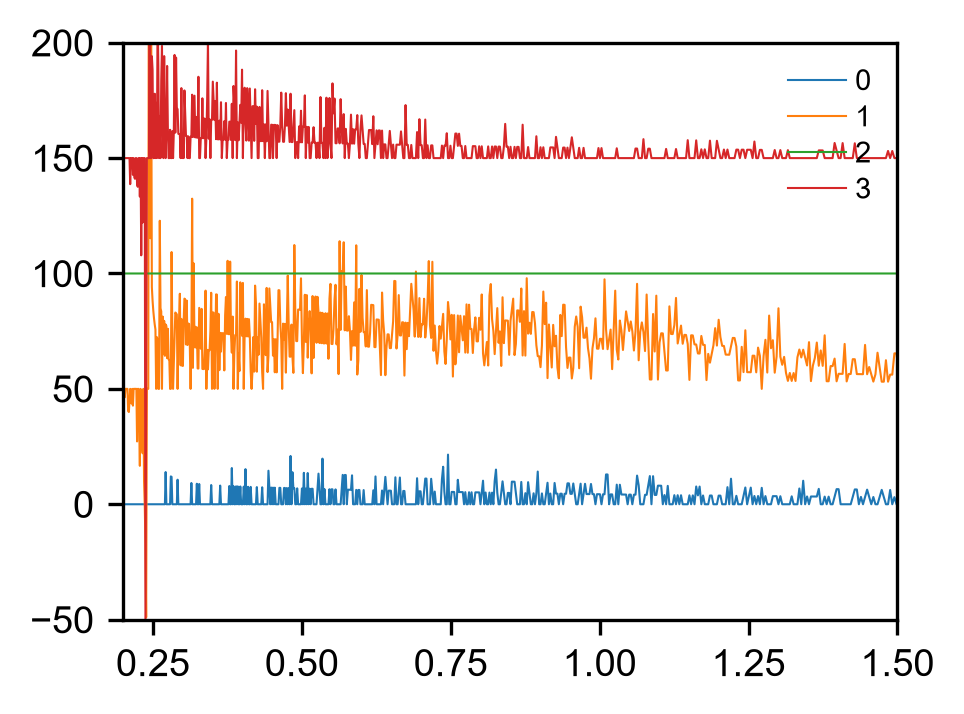

In [21]:
scan = scanSet[1]
#Here ind the index of the time delay
ind= 6 #0 to (len(delays)/4)-1

ind*=4

for i,spectrum in enumerate(scan.spectra[ind:ind+4]):
    print(f"{scan.delays[ind]} mm")
    plt.plot(spectrum[0],spectrum[1]+i*50,lw=.5,label=i)
plt.xlim(0.2,1.5)
plt.ylim(-50,200)
plt.legend()

### Get subtracted spectra

In [22]:
#Here you subtract pump probe and nothing from pp
print(scanSet[0].date)
for scan in scanSet:
    scan.subtract_background(1,3,0,2)

180625


In [31]:
scan = scanSet[1]
subtracted_rebinned = []
rebins = 20
startRebins = int(rebins/2)

for spectrum in scan.subtracted:
    spectrum = spectrum[:,np.logical_and(spectrum[0]>=.30,spectrum[0]<=5)]
    rebinned_spectrum = reduceBins(spectrum,rebins)
    subtracted_rebinned.append(rebinned_spectrum)
subtracted_rebinned = np.array(subtracted_rebinned)


In [37]:
scan.subtracted[0,0]

array([470.68414748, 480.60206234, 490.83616332, ...,  -0.84770505,
        -0.84772289,  -0.84774073], shape=(8000,))

Text(0, 0.5, 'Pump-probe delay / ps')

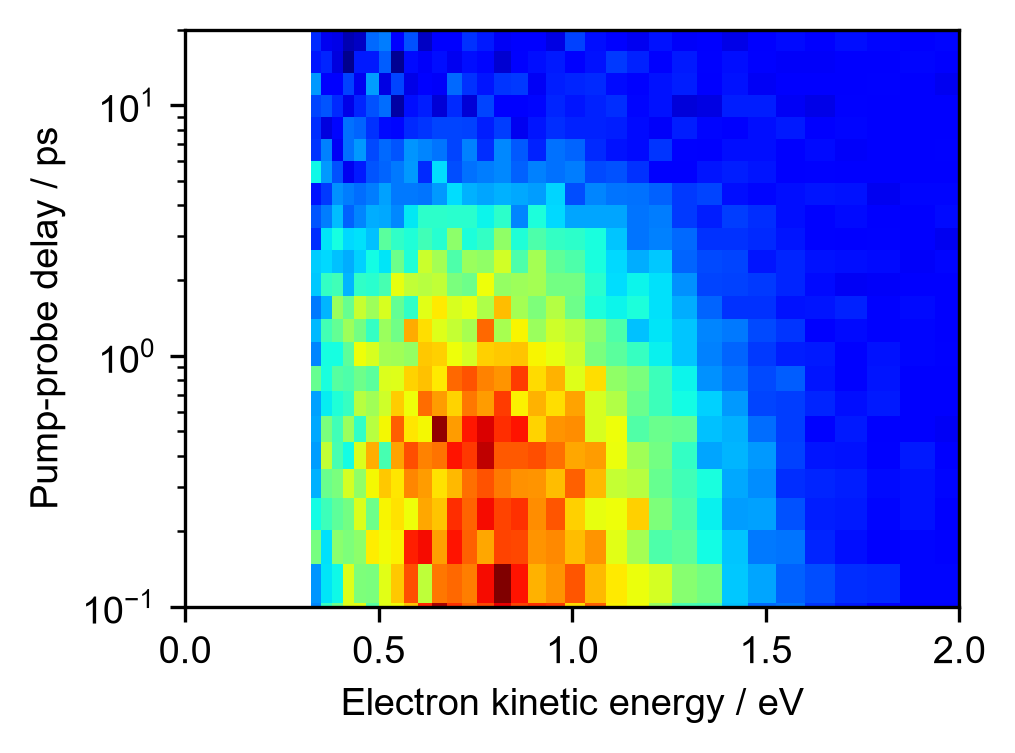

In [45]:
fig,ax = plt.subplots()

im0 = ax.pcolormesh(subtracted_rebinned[0,0],
                    scan.delayTimes,
                    subtracted_rebinned[:,1],
                    cmap='jet',
                    # shading='gouraud',
                   )



ax.set_yscale('log')
ax.set_xlim(0,2)
ax.set_ylim(.1,20)
ax.set_xlabel("Electron kinetic energy / eV")
ax.set_ylabel("Pump-probe delay / ps")